In [66]:
import os
import scanpy as sc
import decoupler as dc
import numpy as np
import pandas as pd
import squidpy as sq
import seaborn as sns
import matplotlib.pyplot as plt

In [49]:
# Pathway activity inference
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

# sample_list = ['15837']

in_dir = '../../results/04_spatial_clustering/01_run_cellcharter/samples'
out_dir = '../../results/04_spatial_clustering/06_pathway_activity'

os.makedirs(f"{out_dir}/samples", exist_ok=True)
os.makedirs(f"{out_dir}/plots", exist_ok=True)

progeny = dc.op.progeny(organism="human")
for sample in sample_list:
    adata = sc.read_h5ad(f'{in_dir}/{sample}.h5ad')
    
    # Normalize the data
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    adata.layers["norm"] = adata.X.copy()

    sc.pp.highly_variable_genes(adata)
    adata = adata[:, adata.var.highly_variable]
    sc.pp.scale(adata)

    dc.mt.ulm(data=adata, net=progeny)

    # Store in new obsm keys
    score = dc.pp.get_obsm(adata=adata, key="score_ulm")

    score.write_h5ad(f'{out_dir}/samples/{sample}.h5ad')

    fig, ax = plt.subplots(4, 4, figsize=(16, 16))

    ax = np.ravel(ax)
    ax = ax[:score.shape[1]]

    sq.pl.spatial_scatter(score, color=score.var_names, cmap='RdBu_r', size=1.5, 
                          ncols=4, fig=fig, ax=ax, return_ax=True)

    fig.tight_layout()
    fig.savefig(f'{out_dir}/plots/{sample}.png', dpi=300)
    plt.close()

In [67]:
# compare pathway activity across samples
df_list = []
for sample in sample_list:
    score = sc.read_h5ad(f'{out_dir}/samples/{sample}.h5ad')
    df = score.to_df()
    df['niche'] = score.obs['cluster_cellcharter'].values
    df_list.append(df)

df = pd.concat(df_list, axis=0)

In [68]:
df.head()

,Androgen,EGFR,Estrogen,Hypoxia,JAK-STAT,MAPK,NFkB,PI3K,TGFb,TNFa,Trail,VEGF,WNT,p53,niche
AACCAAGGTATCAGGC-1,1.488746,1.064081,1.710706,5.277625,1.728363,2.240423,0.778908,3.824717,0.930157,-0.792609,-0.471765,1.709012,1.141579,1.453289,3
AACCGCCAGACTACTT-1,0.627587,0.591755,0.475854,-0.358964,-0.292712,0.782831,-0.569113,0.786963,0.103777,-0.077105,-0.128058,-2.279131,-1.576950,-0.336513,1
AACGAATTGACCGGTT-1,0.488434,-1.576606,-0.157503,0.370991,-0.301489,-0.536212,-0.135034,-1.588040,-0.558021,0.011246,0.886971,0.129161,0.349234,2.001416,8
AACTCAACCTTGACCA-1,-1.264405,-1.105213,0.922297,-1.488366,-0.298940,-0.503078,-1.226070,-1.280343,0.407597,-0.821678,-0.358468,-0.203966,0.500375,0.552284,1
AACTGCCTCGATAGGT-1,-0.213283,-1.075199,-0.971719,0.049362,-1.006607,-0.438190,0.747261,-0.644108,-0.178319,1.305164,0.705575,-0.493496,2.426814,-0.767161,1


In [84]:
# compute average pathway activity per niche per sample
mean_df = df.groupby(['niche']).mean().reset_index()
mean_df.set_index('niche', inplace=True)

In [88]:
# normalize per column
mean_df = (mean_df - mean_df.mean(axis=0)) / mean_df.std(axis=0)

In [89]:
mean_df

,Androgen,EGFR,Estrogen,Hypoxia,JAK-STAT,MAPK,NFkB,PI3K,TGFb,TNFa,Trail,VEGF,WNT,p53
niche,,,,,,,,,,,,,,
0,-0.752732,-1.161849,0.420948,0.932068,-1.078821,-0.942117,-0.079587,-0.843883,-1.094120,-0.484714,-0.782242,-1.382575,1.178191,0.260422
1,-0.769536,-0.801687,-0.746672,-0.603194,-0.015315,-0.728584,-0.052068,-0.866928,-0.758935,0.151801,0.243309,0.880469,-0.183906,-0.335470
10,0.940855,1.616125,-0.453216,0.948517,1.187492,1.921341,1.341470,1.240322,0.592507,1.423508,-0.614737,-0.806777,0.675413,-0.107486
11,0.179787,-1.426805,0.170266,-0.634354,-1.822079,-1.360376,-1.170322,-0.926364,-0.712687,-1.237527,-0.588711,-0.875734,-0.380486,0.881331
12,-0.072932,-1.034527,0.513519,-1.014228,-0.868077,-1.227587,-0.385573,-1.641274,-1.014910,0.070577,0.036098,2.265495,-1.335088,0.621059
2,2.611185,0.444777,-1.550456,1.401536,-0.611756,-0.224746,-0.654481,1.352956,1.338509,-1.207854,-1.833393,0.937099,-2.061942,2.217773
3,0.646092,1.224629,-1.845040,0.716880,0.830987,1.150558,0.551966,0.775885,0.420558,0.395854,0.371170,0.239778,0.171664,-0.497722
4,-0.053066,-0.165238,-0.080459,-0.810876,-0.412565,-0.024499,-1.017507,-0.700033,-0.602212,-0.990721,-0.178046,0.134215,-1.016848,-0.463249
5,-0.085481,-0.540725,1.723839,-0.440861,-0.586994,-0.198347,-0.640483,-0.412137,-1.165405,-0.733690,-0.957329,-0.952930,0.484448,-0.144955


<Figure size 1000x600 with 0 Axes>

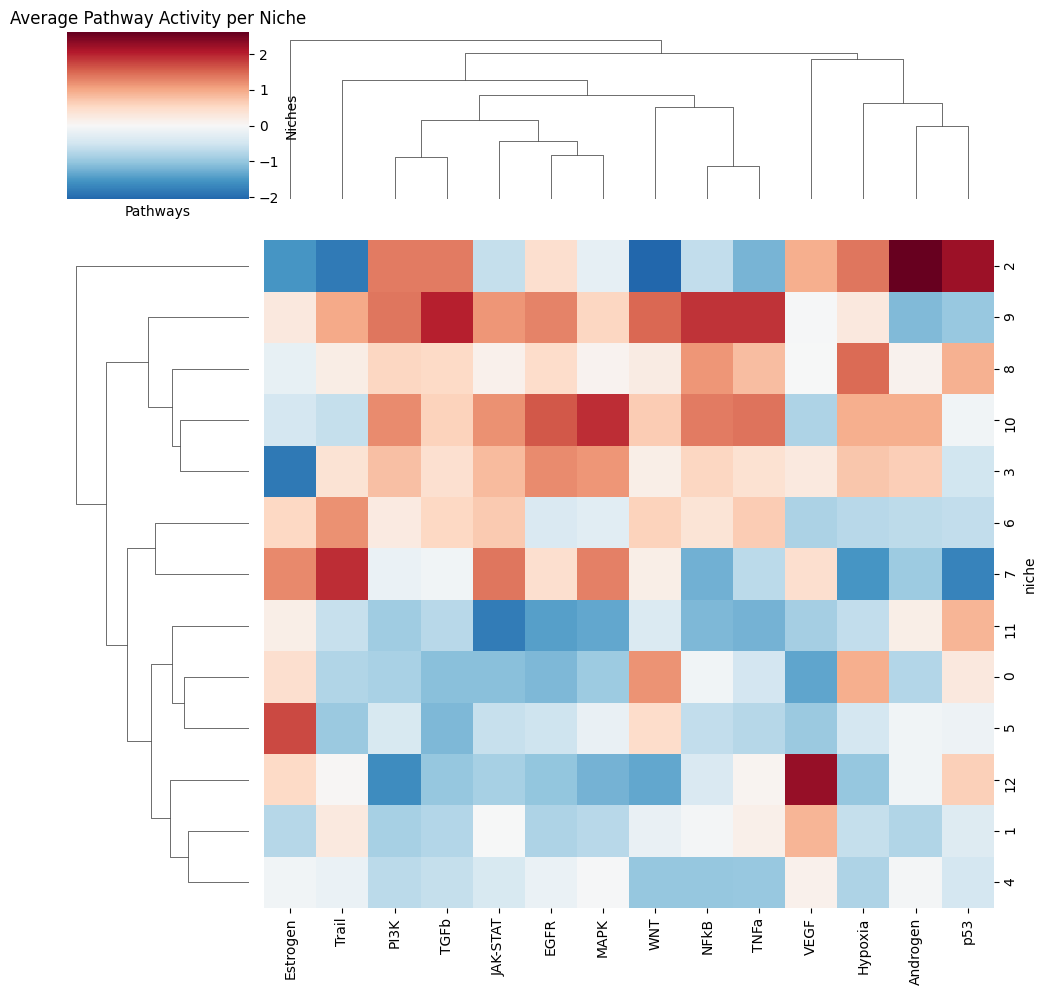

In [92]:
# plot heatmap
plt.figure(figsize=(10, 6))
sns.clustermap(mean_df, cmap='RdBu_r', center=0)
plt.title('Average Pathway Activity per Niche')
plt.xlabel('Pathways')
plt.ylabel('Niches')
plt.tight_layout()